# Activity 1 — Integration with real CO₂ data

**COM7024 · Lesson 7 · SciPy**  
Real question: How large is the accumulated concentration above a chosen baseline? Suggested time: 20 minutes.

**How to use:** Run the cells from top to bottom. Every example works with the supplied full dataset.

## Step 0 — Find the data folder

This short setup supports your GitHub layout: `app/L7/` for notebooks and `data/` at the repository root.

In [1]:
from pathlib import Path

# The data folder is at the root of your GitHub repository.
DATA = Path("data")                 # If Jupyter starts at the repository root
if not DATA.exists():
    DATA = Path("../../data")       # If Jupyter starts inside app/L7
if not DATA.exists():
    DATA = Path("../data")          # If notebooks are in a separate folder

print("Data folder:", DATA.resolve())

Data folder: /workspaces/ProgrammongForDA/data


## 1. Load the weekly measurements

Use the full dataset. Some observations are missing.

In [2]:
import pandas as pd

df = pd.read_csv(DATA / "MaunaLoa_CO2_Full.csv", parse_dates=["date"])
print("Rows:", len(df))
print("Missing CO2 readings:", df["co2_ppm"].isna().sum())
display(df.head())

Rows: 2284
Missing CO2 readings: 59


,date,co2_ppm
0,1958-03-29,316.1
1,1958-04-05,317.3
2,1958-04-12,317.6
3,1958-04-19,317.5
4,1958-04-26,316.4


## 2. Learn `quad` with an easy example

Integrate `x²` between 0 and 2. `error` is an estimated numerical error, not a second area.

In [3]:
from scipy.integrate import quad

def f(x):
    return x**2

I, error = quad(f, 0, 2)
print("Integral:", round(I, 4))
print("Estimated error:", error)

Integral: 2.6667
Estimated error: 2.960594732333751e-14


## 3. Prepare the real data

Fill gaps between observations. Convert dates into elapsed years.

In [4]:
df["co2_filled"] = df["co2_ppm"].interpolate()
df["years"] = (df["date"] - df["date"].min()).dt.days / 365.25

df["above_315"] = df["co2_filled"] - 315
print(df[["date", "above_315"]].head())

        date  above_315
0 1958-03-29        1.1
1 1958-04-05        2.3
2 1958-04-12        2.6
3 1958-04-19        2.5
4 1958-04-26        1.4


## 4. Calculate the accumulated concentration

`trapezoid` and `simpson` work directly with sampled data. **315 ppm is an illustrative reference**, not a historical emissions target.

In [5]:
from scipy.integrate import trapezoid, simpson

x = df["years"]
y = df["above_315"]

trap_result = trapezoid(y, x=x)
simpson_result = simpson(y, x=x)
print("Trapezoid:", round(trap_result, 2), "ppm-years")
print("Simpson:", round(simpson_result, 2), "ppm-years")

Trapezoid: 1078.56 ppm-years
Simpson: 1078.54 ppm-years


## 5. Draw the data you integrated

The curve shows concentration relative to the 315 ppm reference.

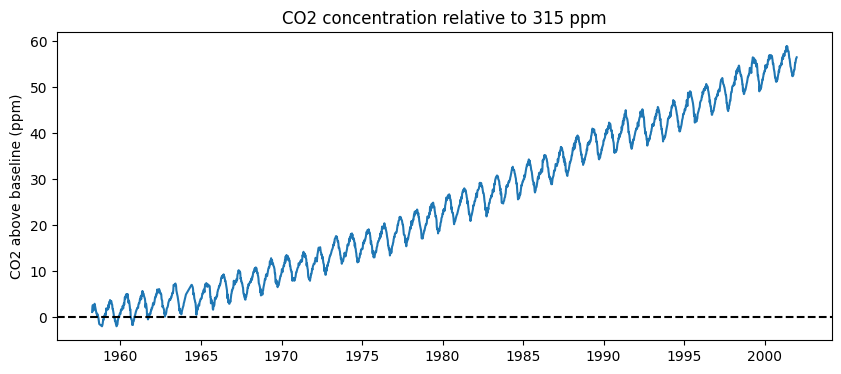

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(df["date"], df["above_315"])
plt.axhline(0, color="black", linestyle="--")
plt.title("CO2 concentration relative to 315 ppm")
plt.ylabel("CO2 above baseline (ppm)")
plt.show()

## Your turn — Quick challenge

Change the reference from **315 ppm to 320 ppm**. Recalculate the trapezoidal result. Is it larger or smaller? Why?

### Before you finish

**Interpretation:** The integral is in **ppm-years**, not tonnes of CO₂ emitted. Interpolating missing values is an assumption and should be reported.